In [ ]:
import os
import zipfile
import xml.etree.ElementTree as ET
import shutil
import random

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from PIL import Image

In [ ]:
zip_path = "/content/archive (2).zip"

print("File exists:", os.path.exists(zip_path))

if os.path.exists(zip_path):
    print("File size:", os.path.getsize(zip_path), "bytes")

File exists: True
File size: 4096 bytes


In [ ]:
zip_path = "/content/archive (2).zip/helmet.zip"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    files_inside = zip_ref.namelist()

print("Total files inside ZIP:", len(files_inside))

print("\nFirst 20 files:")
for file in files_inside[:20]:
    print(file)

Total files inside ZIP: 1528

First 20 files:
annotations/BikesHelmets0.xml
annotations/BikesHelmets1.xml
annotations/BikesHelmets10.xml
annotations/BikesHelmets100.xml
annotations/BikesHelmets101.xml
annotations/BikesHelmets102.xml
annotations/BikesHelmets103.xml
annotations/BikesHelmets104.xml
annotations/BikesHelmets105.xml
annotations/BikesHelmets106.xml
annotations/BikesHelmets107.xml
annotations/BikesHelmets108.xml
annotations/BikesHelmets109.xml
annotations/BikesHelmets11.xml
annotations/BikesHelmets110.xml
annotations/BikesHelmets111.xml
annotations/BikesHelmets112.xml
annotations/BikesHelmets113.xml
annotations/BikesHelmets114.xml
annotations/BikesHelmets115.xml


In [ ]:
extract_path = "/content/helmet_project"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extracted successfully!")

Dataset extracted successfully!


In [ ]:
#Check the extracted folder structure
for root, dirs, files in os.walk(extract_path):
    level = root.replace(extract_path, "").count(os.sep)
    indent = "  " * level

    print(indent + os.path.basename(root) + "/")

    for file in files[:5]:
        print(indent + "  " + file)

helmet_project/
  annotations/
    BikesHelmets49.xml
    BikesHelmets684.xml
    BikesHelmets506.xml
    BikesHelmets244.xml
    BikesHelmets44.xml
  images/
    BikesHelmets670.png
    BikesHelmets562.png
    BikesHelmets53.png
    BikesHelmets575.png
    BikesHelmets358.png


In [ ]:
#Set the dataset paths
ANNOTATION_DIR = "/content/helmet_project/annotations"
IMAGE_DIR = "/content/helmet_project/images"

print("Annotation folder exists:", os.path.exists(ANNOTATION_DIR))
print("Image folder exists:", os.path.exists(IMAGE_DIR))

Annotation folder exists: True
Image folder exists: True


In [ ]:
#Read the XML annotations
records = []

for xml_file in os.listdir(ANNOTATION_DIR):

    if not xml_file.endswith(".xml"):
        continue

    xml_path = os.path.join(ANNOTATION_DIR, xml_file)

    tree = ET.parse(xml_path)
    root = tree.getroot()

    filename = root.find("filename").text

    size = root.find("size")
    image_width = int(size.find("width").text)
    image_height = int(size.find("height").text)

    for obj in root.findall("object"):

        class_name = obj.find("name").text

        bbox = obj.find("bndbox")

        xmin = int(float(bbox.find("xmin").text))
        ymin = int(float(bbox.find("ymin").text))
        xmax = int(float(bbox.find("xmax").text))
        ymax = int(float(bbox.find("ymax").text))

        box_width = xmax - xmin
        box_height = ymax - ymin

        box_area = box_width * box_height

        aspect_ratio = (
            box_width / box_height
            if box_height > 0
            else 0
        )

        records.append({
            "filename": filename,
            "class": class_name,
            "image_width": image_width,
            "image_height": image_height,
            "xmin": xmin,
            "ymin": ymin,
            "xmax": xmax,
            "ymax": ymax,
            "box_width": box_width,
            "box_height": box_height,
            "box_area": box_area,
            "aspect_ratio": aspect_ratio
        })

print("XML annotations read successfully!")
print("Total annotation records:", len(records))

XML annotations read successfully!
Total annotation records: 1451


In [ ]:
#Create the DataFrame
df = pd.DataFrame(records)

print("Total bounding boxes:", len(df))
print("Total images:", df["filename"].nunique())

display(df.head())


Total bounding boxes: 1451
Total images: 761


,filename,class,image_width,image_height,xmin,ymin,xmax,ymax,box_width,box_height,box_area,aspect_ratio
0,BikesHelmets49.png,With Helmet,400,250,174,24,216,73,42,49,2058,0.857143
1,BikesHelmets49.png,Without Helmet,400,250,257,19,288,54,31,35,1085,0.885714
2,BikesHelmets684.png,Without Helmet,267,400,87,10,142,69,55,59,3245,0.932203
3,BikesHelmets506.png,With Helmet,500,428,197,11,301,124,104,113,11752,0.920354
4,BikesHelmets244.png,With Helmet,400,138,270,42,285,55,15,13,195,1.153846


In [ ]:
#Dataset Overview
print("========== DATASET OVERVIEW ==========")

print("Total images:", df["filename"].nunique())
print("Total annotations:", len(df))
print("Total classes:", df["class"].nunique())

print("\nClasses:")
print(df["class"].unique())

========== DATASET OVERVIEW ==========
Total images: 761
Total annotations: 1451
Total classes: 2

Classes:
['With Helmet' 'Without Helmet']


In [ ]:
#Class Distribution
class_counts = df["class"].value_counts()

print("Class Distribution:")
print(class_counts)

Class Distribution:
class
With Helmet       962
Without Helmet    489
Name: count, dtype: int64


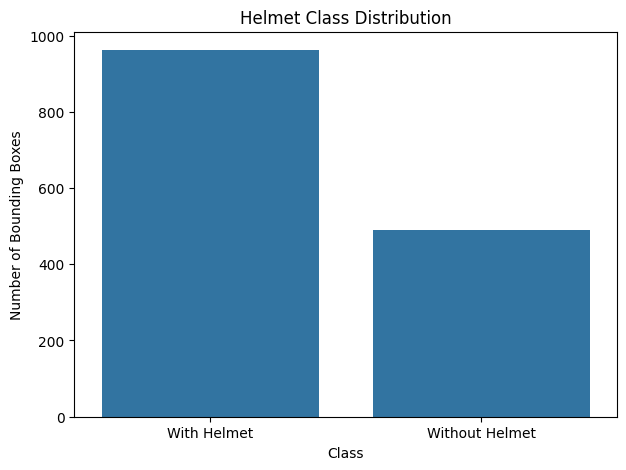

In [ ]:
#Visualize the class distribution
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="class"
)

plt.title("Helmet Class Distribution")
plt.xlabel("Class")
plt.ylabel("Number of Bounding Boxes")

plt.show()

In [ ]:
#Number of annotations per image
annotations_per_image = df.groupby("filename").size()

print("Average annotations per image:", annotations_per_image.mean())
print("Minimum annotations in an image:", annotations_per_image.min())
print("Maximum annotations in an image:", annotations_per_image.max())

Average annotations per image: 1.9067017082785809
Minimum annotations in an image: 1
Maximum annotations in an image: 11


In [ ]:
#Find images with multiple annotations
multiple_annotation_images = annotations_per_image[
    annotations_per_image > 1
]

print("Images with multiple annotations:",
      len(multiple_annotation_images))

print("\nTop 10 images with most annotations:")
print(
    multiple_annotation_images
    .sort_values(ascending=False)
    .head(10)
)

Images with multiple annotations: 336

Top 10 images with most annotations:
filename
BikesHelmets297.png    11
BikesHelmets439.png    10
BikesHelmets351.png     9
BikesHelmets353.png     9
BikesHelmets354.png     8
BikesHelmets303.png     8
BikesHelmets605.png     7
BikesHelmets91.png      7
BikesHelmets164.png     7
BikesHelmets334.png     7
dtype: int64


In [ ]:
#Images containing both classes
classes_per_image = df.groupby("filename")["class"].nunique()

both_classes_images = classes_per_image[
    classes_per_image == 2
]

print("Images containing both classes:",
      len(both_classes_images))

print("\nSample images:")
print(both_classes_images.head(10))

Images containing both classes: 54

Sample images:
filename
BikesHelmets116.png    2
BikesHelmets138.png    2
BikesHelmets150.png    2
BikesHelmets154.png    2
BikesHelmets171.png    2
BikesHelmets194.png    2
BikesHelmets208.png    2
BikesHelmets220.png    2
BikesHelmets231.png    2
BikesHelmets293.png    2
Name: class, dtype: int64


In [ ]:
#Bounding-box width and height analysis
print("Bounding Box Width Statistics:")
print(df["box_width"].describe())

print("\nBounding Box Height Statistics:")
print(df["box_height"].describe())

Bounding Box Width Statistics:
count     1451.000000
mean       424.203308
std       3684.860355
min          8.000000
25%         25.000000
50%         38.000000
75%         54.000000
max      52866.000000
Name: box_width, dtype: float64

Bounding Box Height Statistics:
count     1451.000000
mean       360.273604
std       3041.489098
min          8.000000
25%         29.000000
50%         42.000000
75%         58.000000
max      40317.000000
Name: box_height, dtype: float64


In [ ]:
#Bounding-box area analysis
print("Bounding Box Area Statistics:")
print(df["box_area"].describe())

Bounding Box Area Statistics:
count    1.451000e+03
mean     1.105858e+07
std      1.163697e+08
min      8.000000e+01
25%      7.250000e+02
50%      1.558000e+03
75%      3.059000e+03
max      2.131399e+09
Name: box_area, dtype: float64


In [ ]:
#Identify invalid bounding boxes
invalid_boxes = df[
    (df["xmin"] < 0) |
    (df["ymin"] < 0) |
    (df["xmax"] > df["image_width"]) |
    (df["ymax"] > df["image_height"]) |
    (df["xmin"] >= df["xmax"]) |
    (df["ymin"] >= df["ymax"])
]

print("Number of invalid bounding boxes:", len(invalid_boxes))

display(
    invalid_boxes[
        [
            "filename",
            "class",
            "image_width",
            "image_height",
            "xmin",
            "ymin",
            "xmax",
            "ymax",
            "box_width",
            "box_height"
        ]
    ].head(20)
)

Number of invalid bounding boxes: 17


,filename,class,image_width,image_height,xmin,ymin,xmax,ymax,box_width,box_height
52,BikesHelmets444.png,Without Helmet,200,159,52000,1272,67600,13992,15600,12720
83,BikesHelmets671.png,Without Helmet,400,240,334800,54000,355600,66480,20800,12480
97,BikesHelmets343.png,With Helmet,400,269,249264,26093,296552,54876,47288,28783
173,BikesHelmets205.png,With Helmet,507,338,112047,2028,155142,27040,43095,25012
298,BikesHelmets616.png,With Helmet,300,200,214800,50400,235200,68600,20400,18200
366,BikesHelmets706.png,Without Helmet,400,300,139600,15000,164000,34500,24400,19500
416,BikesHelmets441.png,Without Helmet,400,300,112000,3000,136400,21900,24400,18900
514,BikesHelmets764.png,With Helmet,400,400,71600,20000,103600,52800,32000,32800
573,BikesHelmets103.png,Without Helmet,400,263,149282,10520,177697,32350,28415,21830
661,BikesHelmets530.png,With Helmet,400,267,104918,4272,145764,35244,40846,30972


In [ ]:
#Check the raw XML for these invalid annotations
invalid_filenames = invalid_boxes["filename"].unique()

print("Invalid annotation images:")
for name in invalid_filenames:
    print(name)

Invalid annotation images:
BikesHelmets444.png
BikesHelmets671.png
BikesHelmets343.png
BikesHelmets205.png
BikesHelmets616.png
BikesHelmets706.png
BikesHelmets441.png
BikesHelmets764.png
BikesHelmets103.png
BikesHelmets530.png
BikesHelmets279.png
BikesHelmets80.png
BikesHelmets140.png
BikesHelmets75.png
BikesHelmets326.png


In [ ]:
#Inspect one invalid XML file
xml_file = "BikesHelmets444.xml"

xml_path = os.path.join(ANNOTATION_DIR, xml_file)

tree = ET.parse(xml_path)
root = tree.getroot()

print("Filename:", root.find("filename").text)

size = root.find("size")
print(
    "Image size:",
    size.find("width").text,
    "x",
    size.find("height").text
)

for obj in root.findall("object"):
    print("\nClass:", obj.find("name").text)

    bbox = obj.find("bndbox")

    print("xmin:", bbox.find("xmin").text)
    print("ymin:", bbox.find("ymin").text)
    print("xmax:", bbox.find("xmax").text)
    print("ymax:", bbox.find("ymax").text)

Filename: BikesHelmets444.png
Image size: 200 x 159

Class: Without Helmet
xmin: 52000
ymin: 1272
xmax: 67600
ymax: 13992

Class: Without Helmet
xmin: 27
ymin: 1
xmax: 56
ymax: 29

Class: Without Helmet
xmin: 86
ymin: 5
xmax: 114
ymax: 33


In [ ]:
#Check whether /1000 fixes all invalid boxes
# Check whether dividing invalid coordinates by 1000
# makes the bounding boxes valid

check = invalid_boxes.copy()

check["xmin_1000"] = check["xmin"] / 1000
check["ymin_1000"] = check["ymin"] / 1000
check["xmax_1000"] = check["xmax"] / 1000
check["ymax_1000"] = check["ymax"] / 1000

check["valid_after_1000"] = (
    (check["xmin_1000"] >= 0) &
    (check["ymin_1000"] >= 0) &
    (check["xmax_1000"] <= check["image_width"]) &
    (check["ymax_1000"] <= check["image_height"]) &
    (check["xmin_1000"] < check["xmax_1000"]) &
    (check["ymin_1000"] < check["ymax_1000"])
)

print("Invalid boxes:", len(check))
print(
    "Valid after dividing by 1000:",
    check["valid_after_1000"].sum()
)

display(
    check[
        [
            "filename",
            "image_width",
            "image_height",
            "xmin",
            "ymin",
            "xmax",
            "ymax",
            "xmin_1000",
            "ymin_1000",
            "xmax_1000",
            "ymax_1000",
            "valid_after_1000"
        ]
    ]
)

Invalid boxes: 17
Valid after dividing by 1000: 17


,filename,image_width,image_height,xmin,ymin,xmax,ymax,xmin_1000,ymin_1000,xmax_1000,ymax_1000,valid_after_1000
52,BikesHelmets444.png,200,159,52000,1272,67600,13992,52.000,1.272,67.600,13.992,True
83,BikesHelmets671.png,400,240,334800,54000,355600,66480,334.800,54.000,355.600,66.480,True
97,BikesHelmets343.png,400,269,249264,26093,296552,54876,249.264,26.093,296.552,54.876,True
173,BikesHelmets205.png,507,338,112047,2028,155142,27040,112.047,2.028,155.142,27.040,True
298,BikesHelmets616.png,300,200,214800,50400,235200,68600,214.800,50.400,235.200,68.600,True
366,BikesHelmets706.png,400,300,139600,15000,164000,34500,139.600,15.000,164.000,34.500,True
416,BikesHelmets441.png,400,300,112000,3000,136400,21900,112.000,3.000,136.400,21.900,True
514,BikesHelmets764.png,400,400,71600,20000,103600,52800,71.600,20.000,103.600,52.800,True
573,BikesHelmets103.png,400,263,149282,10520,177697,32350,149.282,10.520,177.697,32.350,True
661,BikesHelmets530.png,400,267,104918,4272,145764,35244,104.918,4.272,145.764,35.244,True


All 17 invalid boxes become valid when divided by 1000:

Invalid boxes: 17
Valid after dividing by 1000: 17

So the /1000 pattern is consistent across all 17 invalid annotations. That gives us good evidence that these particular XML coordinates were stored at a 1000× scale.

In [ ]:
# Create corrected DataFrame
df_corrected = df.copy()

# Convert bounding-box coordinates to float
for col in ["xmin", "ymin", "xmax", "ymax"]:
    df_corrected[col] = df_corrected[col].astype(float)

invalid_mask = (
    (df_corrected["xmin"] < 0) |
    (df_corrected["ymin"] < 0) |
    (df_corrected["xmax"] > df_corrected["image_width"]) |
    (df_corrected["ymax"] > df_corrected["image_height"]) |
    (df_corrected["xmin"] >= df_corrected["xmax"]) |
    (df_corrected["ymin"] >= df_corrected["ymax"])
)

# Correct the 17 invalid bounding boxes
for col in ["xmin", "ymin", "xmax", "ymax"]:
    df_corrected.loc[invalid_mask, col] = (
        df_corrected.loc[invalid_mask, col] / 1000
    )

# Recalculate bounding-box measurements
df_corrected["box_width"] = (
    df_corrected["xmax"] - df_corrected["xmin"]
)

df_corrected["box_height"] = (
    df_corrected["ymax"] - df_corrected["ymin"]
)

df_corrected["box_area"] = (
    df_corrected["box_width"] *
    df_corrected["box_height"]
)

df_corrected["aspect_ratio"] = (
    df_corrected["box_width"] /
    df_corrected["box_height"]
)

print("Corrected bounding boxes:", invalid_mask.sum())

Corrected bounding boxes: 17


In [ ]:
#Missing Values Check:
# Check for missing values

print("Missing values in each column:")
print(df_corrected.isnull().sum())

Missing values in each column:
filename        0
class           0
image_width     0
image_height    0
xmin            0
ymin            0
xmax            0
ymax            0
box_width       0
box_height      0
box_area        0
aspect_ratio    0
dtype: int64


In [ ]:
#Duplicate Annotation Check


duplicates = df_corrected.duplicated().sum()

print("Duplicate annotation rows:", duplicates)

Duplicate annotation rows: 0


In [ ]:
#Image Dimension Analysis


print("Image Width Statistics:")
print(df_corrected["image_width"].describe())

print("\nImage Height Statistics:")
print(df_corrected["image_height"].describe())

Image Width Statistics:
count    1451.000000
mean      406.223983
std        66.184967
min       150.000000
25%       400.000000
50%       400.000000
75%       400.000000
max       600.000000
Name: image_width, dtype: float64

Image Height Statistics:
count    1451.000000
mean      288.113025
std        70.132089
min       114.000000
25%       246.500000
50%       267.000000
75%       305.000000
max       600.000000
Name: image_height, dtype: float64


In [ ]:
#Bounding Box Relative Size #This tells us how large each annotated rider/helmet region is compared with the full image.


df_corrected["box_area_ratio"] = (
    df_corrected["box_area"] /
    (df_corrected["image_width"] * df_corrected["image_height"])
)

print("Bounding Box Area Ratio Statistics:")
print(df_corrected["box_area_ratio"].describe())

Bounding Box Area Ratio Statistics:
count    1451.000000
mean        0.020152
std         0.022488
min         0.000664
25%         0.006970
50%         0.013876
75%         0.024346
max         0.293272
Name: box_area_ratio, dtype: float64


In [ ]:
#Class-wise Bounding Box Analysis


print("Average Bounding Box Size by Class:")

class_bbox_stats = df_corrected.groupby("class")[[
    "box_width",
    "box_height",
    "box_area",
    "box_area_ratio"
]].mean()

display(class_bbox_stats)

Average Bounding Box Size by Class:


,box_width,box_height,box_area,box_area_ratio
class,,,,
With Helmet,46.333294,51.036140,2968.579776,0.024030
Without Helmet,32.703233,36.830959,1497.612856,0.012522


So, on average, the annotated regions for With Helmet are larger than those for Without Helmet.

In [ ]:
#Aspect Ratio Analysis


print("Overall Aspect Ratio Statistics:")
print(df_corrected["aspect_ratio"].describe())

print("\nAverage Aspect Ratio by Class:")

aspect_ratio_by_class = df_corrected.groupby("class")["aspect_ratio"].mean()

display(aspect_ratio_by_class)

Overall Aspect Ratio Statistics:
count    1451.000000
mean        0.912461
std         0.147818
min         0.534884
25%         0.809524
50%         0.903846
75%         1.000000
max         2.625000
Name: aspect_ratio, dtype: float64

Average Aspect Ratio by Class:


,aspect_ratio
class,
With Helmet,0.918181
Without Helmet,0.901209


In [ ]:
#Duplicate Annotation Check

duplicate_rows = df_corrected.duplicated(
    subset=["filename", "class", "xmin", "ymin", "xmax", "ymax"]
)

print("Number of duplicate annotations:", duplicate_rows.sum())

if duplicate_rows.sum() > 0:
    print("\nDuplicate annotations:")
    display(df_corrected[duplicate_rows])
else:
    print("No duplicate annotations found.")

Number of duplicate annotations: 0
No duplicate annotations found.


In [ ]:
#Check image files against annotations


IMAGE_DIR = "/content/helmet_project/images"

annotated_images = set(df_corrected["filename"])
available_images = set(os.listdir(IMAGE_DIR))

missing_images = annotated_images - available_images

print("Total annotated images:", len(annotated_images))
print("Total available image files:", len(available_images))
print("Missing images:", len(missing_images))

if len(missing_images) > 0:
    print("\nMissing image files:")
    for img in sorted(missing_images):
        print(img)
else:
    print("All annotated images are available.")

Total annotated images: 761
Total available image files: 764
Missing images: 0
All annotated images are available.


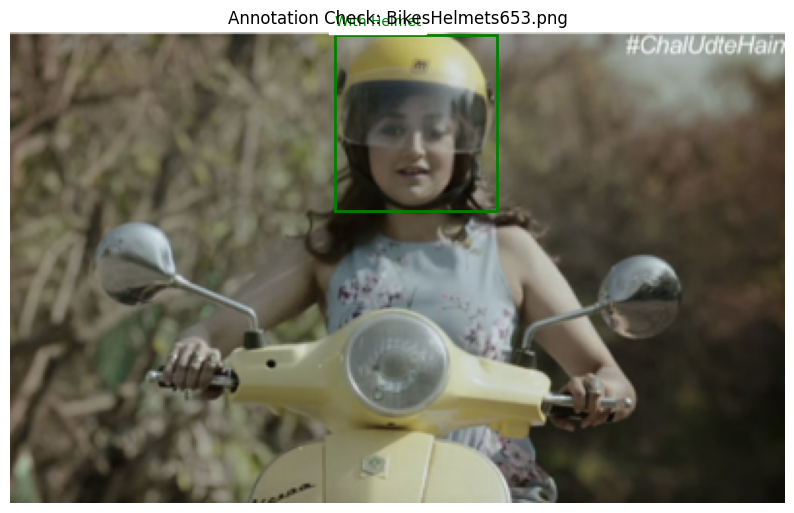

In [ ]:
#Visual Annotation Audit


import random

sample_image = random.choice(df_corrected["filename"].unique())

image_path = os.path.join(IMAGE_DIR, sample_image)

img = Image.open(image_path)

plt.figure(figsize=(10, 7))
plt.imshow(img)

image_data = df_corrected[
    df_corrected["filename"] == sample_image
]

for _, row in image_data.iterrows():

    if row["class"] == "Without Helmet":
        color = "red"
    else:
        color = "green"

    rectangle = plt.Rectangle(
        (row["xmin"], row["ymin"]),
        row["box_width"],
        row["box_height"],
        fill=False,
        edgecolor=color,
        linewidth=2
    )

    plt.gca().add_patch(rectangle)

    plt.text(
        row["xmin"],
        row["ymin"] - 5,
        row["class"],
        color=color,
        fontsize=10,
        backgroundcolor="white"
    )

plt.title(f"Annotation Check: {sample_image}")
plt.axis("off")
plt.show()

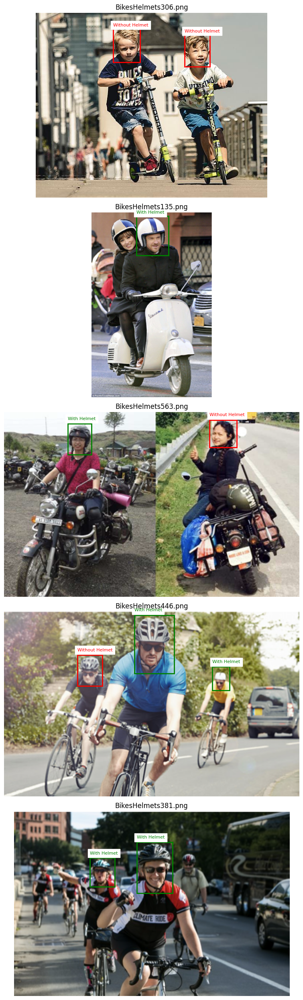

In [ ]:
#check several images automatically
# Visual Audit - 5 Random Images

sample_images = random.sample(
    list(df_corrected["filename"].unique()),
    5
)

fig, axes = plt.subplots(5, 1, figsize=(12, 25))

for ax, sample_image in zip(axes, sample_images):

    image_path = os.path.join(IMAGE_DIR, sample_image)
    img = Image.open(image_path)

    ax.imshow(img)

    image_data = df_corrected[
        df_corrected["filename"] == sample_image
    ]

    for _, row in image_data.iterrows():

        color = "red" if row["class"] == "Without Helmet" else "green"

        rectangle = plt.Rectangle(
            (row["xmin"], row["ymin"]),
            row["box_width"],
            row["box_height"],
            fill=False,
            edgecolor=color,
            linewidth=2
        )

        ax.add_patch(rectangle)

        ax.text(
            row["xmin"],
            row["ymin"] - 5,
            row["class"],
            color=color,
            fontsize=8,
            backgroundcolor="white"
        )

    ax.set_title(sample_image)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
## Annotation Coverage by Class

class_counts_per_image = df_corrected.groupby(
    "filename"
)["class"].nunique()

only_one_class = (class_counts_per_image == 1).sum()
both_classes = (class_counts_per_image == 2).sum()

print("Images with only one class:", only_one_class)
print("Images with both classes:", both_classes)
print("Total annotated images:", len(class_counts_per_image))

Images with only one class: 707
Images with both classes: 54
Total annotated images: 761


In [ ]:

# Annotation Count per Image

annotations_per_image = df_corrected.groupby("filename").size()

print("Annotation Count Statistics:")
print(annotations_per_image.describe())

Annotation Count Statistics:
count    761.000000
mean       1.906702
std        1.429195
min        1.000000
25%        1.000000
50%        1.000000
75%        2.000000
max       11.000000
dtype: float64


In [ ]:
## Images with multiple annotations
multiple_annotation_images = annotations_per_image[
    annotations_per_image > 1
]

print("Images with multiple annotations:", len(multiple_annotation_images))
print("\nTop images by annotation count:")
print(multiple_annotation_images.sort_values(ascending=False).head(10))

Images with multiple annotations: 336

Top images by annotation count:
filename
BikesHelmets297.png    11
BikesHelmets439.png    10
BikesHelmets351.png     9
BikesHelmets353.png     9
BikesHelmets354.png     8
BikesHelmets303.png     8
BikesHelmets605.png     7
BikesHelmets91.png      7
BikesHelmets164.png     7
BikesHelmets334.png     7
dtype: int64


In [ ]:
## Manual Review Candidates
# Identify images with 3 or more annotations
# These images are more useful for checking rider/passenger coverage

audit_candidates = annotations_per_image[
    annotations_per_image >= 3
].sort_values(ascending=False)

print("Images with 3 or more annotations:", len(audit_candidates))

print("\nTop images for manual review:")
print(audit_candidates.head(20))

Images with 3 or more annotations: 163

Top images for manual review:
filename
BikesHelmets297.png    11
BikesHelmets439.png    10
BikesHelmets353.png     9
BikesHelmets351.png     9
BikesHelmets354.png     8
BikesHelmets303.png     8
BikesHelmets334.png     7
BikesHelmets605.png     7
BikesHelmets164.png     7
BikesHelmets740.png     7
BikesHelmets91.png      7
BikesHelmets131.png     7
BikesHelmets137.png     7
BikesHelmets215.png     6
BikesHelmets152.png     6
BikesHelmets70.png      6
BikesHelmets64.png      6
BikesHelmets11.png      6
BikesHelmets555.png     6
BikesHelmets399.png     6
dtype: int64


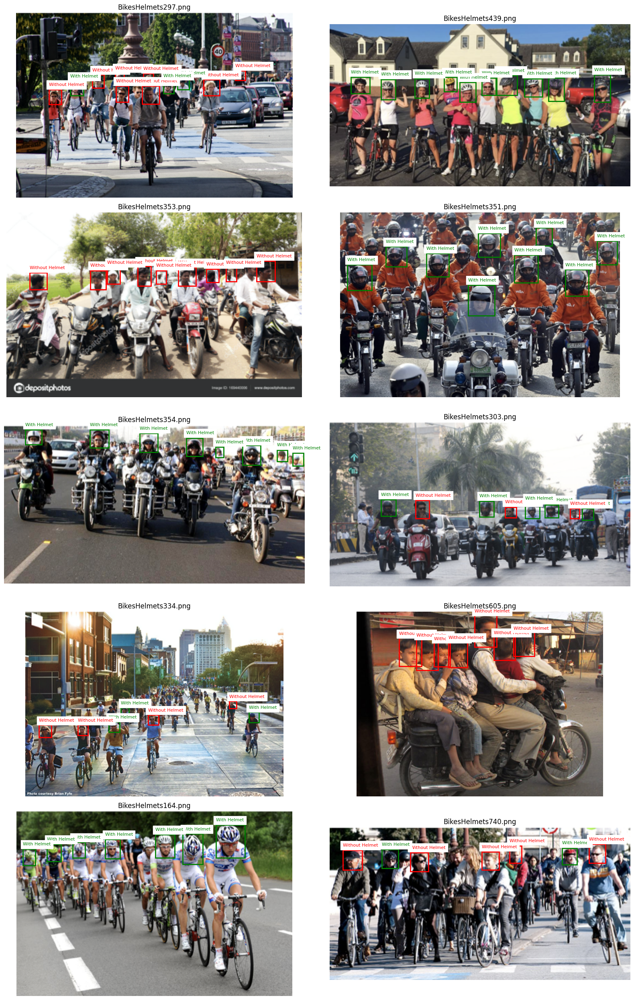

In [ ]:
#show top 10 audit images
# Visual Audit of Top 10 Multi-Annotation Images

top_audit_images = audit_candidates.head(10).index.tolist()

fig, axes = plt.subplots(5, 2, figsize=(16, 25))
axes = axes.flatten()

for ax, image_name in zip(axes, top_audit_images):

    image_path = os.path.join(IMAGE_DIR, image_name)
    img = Image.open(image_path)

    ax.imshow(img)

    image_data = df_corrected[
        df_corrected["filename"] == image_name
    ]

    for _, row in image_data.iterrows():

        if row["class"] == "Without Helmet":
            color = "red"
        else:
            color = "green"

        rectangle = plt.Rectangle(
            (row["xmin"], row["ymin"]),
            row["box_width"],
            row["box_height"],
            fill=False,
            edgecolor=color,
            linewidth=2
        )

        ax.add_patch(rectangle)

        ax.text(
            row["xmin"],
            row["ymin"] - 5,
            row["class"],
            color=color,
            fontsize=8,
            backgroundcolor="white"
        )

    ax.set_title(image_name)
    ax.axis("off")

plt.tight_layout()
plt.show()


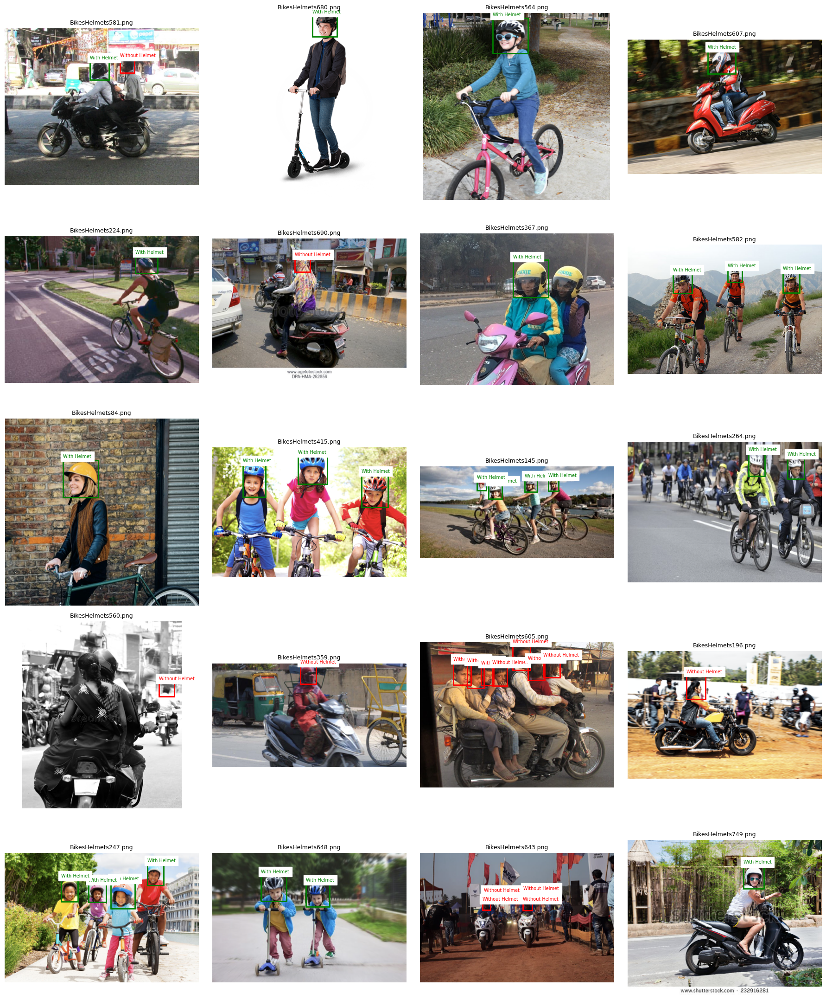

In [ ]:
# Visual Audit - 20 Representative Images

import random

# Select 20 images randomly
sample_images = random.sample(
    list(df_corrected["filename"].unique()),
    min(20, len(df_corrected["filename"].unique()))
)

fig, axes = plt.subplots(5, 4, figsize=(18, 22))
axes = axes.flatten()

for ax, sample_image in zip(axes, sample_images):

    image_path = os.path.join(IMAGE_DIR, sample_image)
    img = Image.open(image_path)

    ax.imshow(img)

    image_data = df_corrected[
        df_corrected["filename"] == sample_image
    ]

    for _, row in image_data.iterrows():

        color = "red" if row["class"] == "Without Helmet" else "green"

        rectangle = plt.Rectangle(
            (row["xmin"], row["ymin"]),
            row["box_width"],
            row["box_height"],
            fill=False,
            edgecolor=color,
            linewidth=2
        )

        ax.add_patch(rectangle)

        ax.text(
            row["xmin"],
            max(row["ymin"] - 5, 0),
            row["class"],
            color=color,
            fontsize=7,
            backgroundcolor="white"
        )

    ax.set_title(sample_image, fontsize=9)
    ax.axis("off")

plt.tight_layout()
plt.show()

Annotation Guidelines

Annotate every clearly visible rider on a motorcycle/scooter.
Annotate both the driver and pillion passenger when they are clearly visible.
Use With Helmet when the rider/passenger is wearing a helmet.
Use Without Helmet when the rider/passenger is not wearing a helmet.
For bicycles, annotate only the cyclist/rider.
Do not annotate pedestrians or unrelated people in the background.
Ignore heavily blurred, extremely small, or unclear people where helmet status cannot be reliably determined.
For crowded scenes, annotate clearly visible relevant riders/passengers in the main focus area.

In [ ]:
# Manual Annotation Review Candidates
# Based on project annotation guidelines

# Calculate relative bounding-box area
df_corrected["box_area_ratio"] = (
    df_corrected["box_area"] /
    (df_corrected["image_width"] * df_corrected["image_height"])
)

# Number of annotations per image
annotations_per_image = df_corrected.groupby("filename").size()

# Images with many annotations
many_annotations = annotations_per_image[
    annotations_per_image >= 3
].index

# Very small bounding boxes
small_boxes = df_corrected[
    df_corrected["box_area_ratio"] < 0.005
]["filename"].unique()

# Images containing small boxes
small_box_images = set(small_boxes)

# Combine candidates
review_candidates = set(many_annotations) | small_box_images

print("========== MANUAL ANNOTATION REVIEW ==========")
print("Total annotated images:", df_corrected["filename"].nunique())
print("Images needing manual review:", len(review_candidates))

print("\nReview candidates:")
for image in sorted(review_candidates):
    print(image)

========== MANUAL ANNOTATION REVIEW ==========
Total annotated images: 761
Images needing manual review: 200

Review candidates:
BikesHelmets0.png
BikesHelmets106.png
BikesHelmets11.png
BikesHelmets110.png
BikesHelmets114.png
BikesHelmets115.png
BikesHelmets116.png
BikesHelmets123.png
BikesHelmets124.png
BikesHelmets126.png
BikesHelmets131.png
BikesHelmets132.png
BikesHelmets134.png
BikesHelmets137.png
BikesHelmets145.png
BikesHelmets146.png
BikesHelmets149.png
BikesHelmets150.png
BikesHelmets152.png
BikesHelmets154.png
BikesHelmets16.png
BikesHelmets160.png
BikesHelmets163.png
BikesHelmets164.png
BikesHelmets171.png
BikesHelmets175.png
BikesHelmets176.png
BikesHelmets180.png
BikesHelmets184.png
BikesHelmets195.png
BikesHelmets2.png
BikesHelmets203.png
BikesHelmets204.png
BikesHelmets208.png
BikesHelmets215.png
BikesHelmets217.png
BikesHelmets219.png
BikesHelmets220.png
BikesHelmets221.png
BikesHelmets222.png
BikesHelmets223.png
BikesHelmets228.png
BikesHelmets23.png
BikesHelmets235.pn

In [ ]:
# Potential Missing Rider/Pillion Annotation Candidates

annotation_counts = df_corrected.groupby("filename").size()

# Images with only 1 annotation
one_annotation_images = annotation_counts[
    annotation_counts == 1
].index

# Images with 2 annotations
two_annotation_images = annotation_counts[
    annotation_counts == 2
].index

print("Images with exactly 1 annotation:", len(one_annotation_images))
print("Images with exactly 2 annotations:", len(two_annotation_images))

print("\nSample images with only 1 annotation:")
print(list(one_annotation_images)[:30])

print("\nSample images with exactly 2 annotations:")
print(list(two_annotation_images)[:30])

Images with exactly 1 annotation: 425
Images with exactly 2 annotations: 173

Sample images with only 1 annotation:
['BikesHelmets1.png', 'BikesHelmets10.png', 'BikesHelmets101.png', 'BikesHelmets102.png', 'BikesHelmets103.png', 'BikesHelmets105.png', 'BikesHelmets107.png', 'BikesHelmets108.png', 'BikesHelmets109.png', 'BikesHelmets111.png', 'BikesHelmets113.png', 'BikesHelmets117.png', 'BikesHelmets118.png', 'BikesHelmets119.png', 'BikesHelmets12.png', 'BikesHelmets120.png', 'BikesHelmets121.png', 'BikesHelmets122.png', 'BikesHelmets123.png', 'BikesHelmets125.png', 'BikesHelmets127.png', 'BikesHelmets129.png', 'BikesHelmets13.png', 'BikesHelmets130.png', 'BikesHelmets133.png', 'BikesHelmets135.png', 'BikesHelmets136.png', 'BikesHelmets139.png', 'BikesHelmets14.png', 'BikesHelmets141.png']

Sample images with exactly 2 annotations:
['BikesHelmets100.png', 'BikesHelmets104.png', 'BikesHelmets110.png', 'BikesHelmets112.png', 'BikesHelmets116.png', 'BikesHelmets128.png', 'BikesHelmets138.

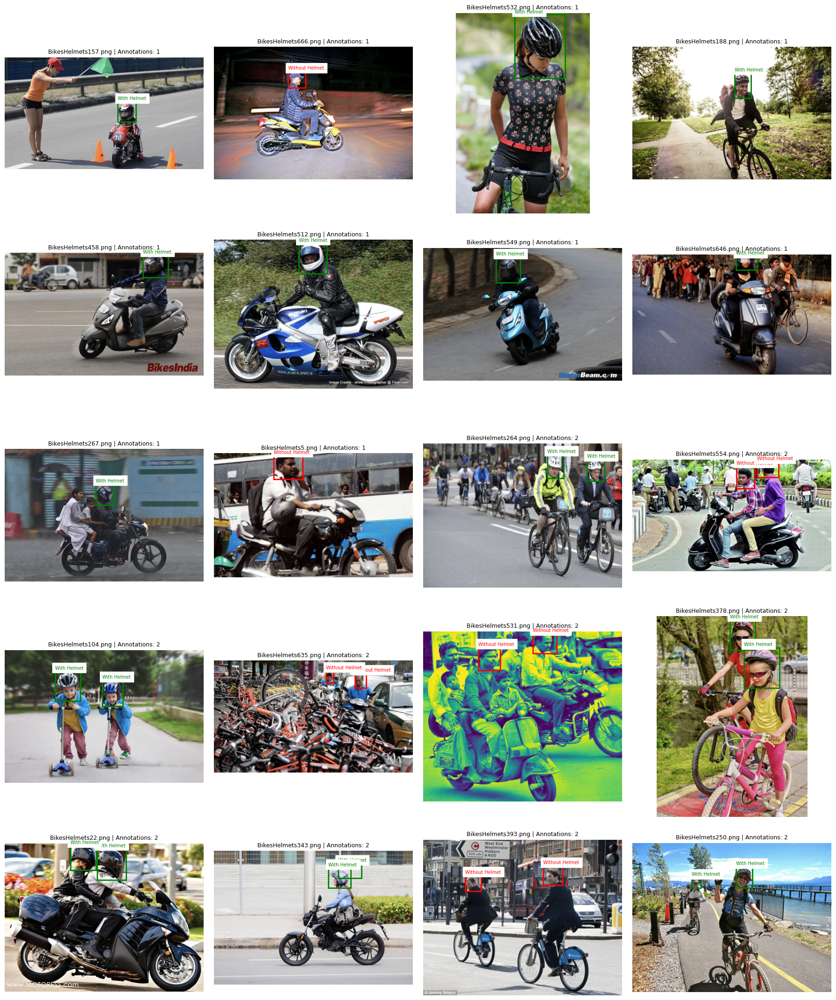

In [ ]:
# Visual Review of Low-Annotation Images

import random

review_images = (
    random.sample(list(one_annotation_images),
                  min(10, len(one_annotation_images)))
    +
    random.sample(list(two_annotation_images),
                  min(10, len(two_annotation_images)))
)

fig, axes = plt.subplots(5, 4, figsize=(18, 22))
axes = axes.flatten()

for ax, sample_image in zip(axes, review_images):

    image_path = os.path.join(IMAGE_DIR, sample_image)
    img = Image.open(image_path)

    ax.imshow(img)

    image_data = df_corrected[
        df_corrected["filename"] == sample_image
    ]

    for _, row in image_data.iterrows():

        color = "red" if row["class"] == "Without Helmet" else "green"

        rectangle = plt.Rectangle(
            (row["xmin"], row["ymin"]),
            row["box_width"],
            row["box_height"],
            fill=False,
            edgecolor=color,
            linewidth=2
        )

        ax.add_patch(rectangle)

        ax.text(
            row["xmin"],
            max(row["ymin"] - 5, 0),
            row["class"],
            color=color,
            fontsize=7,
            backgroundcolor="white"
        )

    ax.set_title(
        f"{sample_image} | Annotations: {len(image_data)}",
        fontsize=9
    )

    ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
# Final validation of corrected bounding boxes
invalid_corrected = df_corrected[
    (df_corrected["xmin"] < 0) |
    (df_corrected["ymin"] < 0) |
    (df_corrected["xmax"] > df_corrected["image_width"]) |
    (df_corrected["ymax"] > df_corrected["image_height"]) |
    (df_corrected["xmin"] >= df_corrected["xmax"]) |
    (df_corrected["ymin"] >= df_corrected["ymax"])
]

print("Invalid bounding boxes after correction:", len(invalid_corrected))

if len(invalid_corrected) == 0:
    print("All corrected bounding boxes are valid.")
else:
    display(invalid_corrected)

Invalid bounding boxes after correction: 0
All corrected bounding boxes are valid.


In [ ]:
# Final class distribution
print("Final class distribution:")
print(df_corrected["class"].value_counts())

print("\nTotal objects:", len(df_corrected))

Final class distribution:
class
With Helmet       962
Without Helmet    489
Name: count, dtype: int64

Total objects: 1451


In [ ]:
# YOLO class mapping
class_mapping = {
    "With Helmet": 0,
    "Without Helmet": 1
}

print("Class mapping:")
print(class_mapping)

Class mapping:
{'With Helmet': 0, 'Without Helmet': 1}


In [ ]:
yolo_root = "/content/helmet_yolo"
for folder in [
    "images/train",
    "images/val",
    "images/test",
    "labels/train",
    "labels/val",
    "labels/test"
]:
    os.makedirs(
        os.path.join(yolo_root, folder),
        exist_ok=True
    )

print("YOLO directory structure created.")

YOLO directory structure created.


In [ ]:
image_files = [
    f for f in os.listdir(IMAGE_DIR)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
]

print("Total images:", len(image_files))

Total images: 764


In [ ]:
# Split the dataset into train, validation and test
random.seed(42)
random.shuffle(image_files)
total = len(image_files)

train_end = int(0.70 * total)
val_end = int(0.90 * total)

train_files = image_files[:train_end]
val_files = image_files[train_end:val_end]
test_files = image_files[val_end:]

print("Total:", len(image_files))
print("Train:", len(train_files))
print("Validation:", len(val_files))
print("Test:", len(test_files))

Total: 764
Train: 534
Validation: 153
Test: 77


In [ ]:
# Convert corrected Pascal VOC-style annotations to YOLO format
def convert_dataframe_to_yolo(image_filename, txt_path):

    image_data = df_corrected[
        df_corrected["filename"] == image_filename
    ]

    yolo_lines = []
    for _, row in image_data.iterrows():
        class_name = row["class"]
        if class_name not in class_mapping:
            continue
        class_id = class_mapping[class_name]

        image_width = row["image_width"]
        image_height = row["image_height"]

        xmin = row["xmin"]
        ymin = row["ymin"]
        xmax = row["xmax"]
        ymax = row["ymax"]

        bbox_width = xmax - xmin
        bbox_height = ymax - ymin

        x_center = (xmin + xmax) / 2
        y_center = (ymin + ymax) / 2

        x_center /= image_width
        y_center /= image_height
        bbox_width /= image_width
        bbox_height /= image_height

        # YOLO format
        yolo_lines.append(
            f"{class_id} "
            f"{x_center:.6f} "
            f"{y_center:.6f} "
            f"{bbox_width:.6f} "
            f"{bbox_height:.6f}"
        )

    with open(txt_path, "w") as f:
        f.write("\n".join(yolo_lines))

In [ ]:
# Convert the complete dataset to YOLO format
splits = {
    "train": train_files,
    "val": val_files,
    "test": test_files
}
for split_name, files in splits.items():
    for image_filename in files:
        # -------------------------
        # Create YOLO label file
        # -------------------------
        txt_filename = (
            os.path.splitext(image_filename)[0] + ".txt"
        )
        txt_path = os.path.join(
            yolo_root,
            "labels",
            split_name,
            txt_filename
        )
        convert_dataframe_to_yolo(
            image_filename,
            txt_path
        )
        # -------------------------
        # Copy image
        # -------------------------

        source_image = os.path.join(
            IMAGE_DIR,
            image_filename
        )
        destination_image = os.path.join(
            yolo_root,
            "images",
            split_name,
            image_filename
        )
        shutil.copy2(
            source_image,
            destination_image
        )
print("VOC-style annotations → YOLO conversion completed.")

VOC-style annotations → YOLO conversion completed.


In [ ]:
for split in ["train", "val", "test"]:
    image_dir = os.path.join(
        yolo_root,
        "images",
        split
    )
    label_dir = os.path.join(
        yolo_root,
        "labels",
        split
    )
    images = [
        f for f in os.listdir(image_dir)
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ]
    labels = [
        f for f in os.listdir(label_dir)
        if f.endswith(".txt")
    ]
    print(
        split,
        "→ Images:", len(images),
        "| Labels:", len(labels)
    )

train → Images: 534 | Labels: 534
val → Images: 153 | Labels: 153
test → Images: 77 | Labels: 77


In [ ]:
# Sample YOLO label
sample_label = os.listdir(
    os.path.join(yolo_root, "labels", "train")
)[0]
sample_label_path = os.path.join(
    yolo_root,
    "labels",
    "train",
    sample_label
)
print("Label file:", sample_label)
print()
with open(sample_label_path, "r") as f:
    print(f.read())

Label file: BikesHelmets247.txt

0 0.776250 0.166667 0.082500 0.161049
0 0.607500 0.325843 0.125000 0.202247
0 0.477500 0.307116 0.090000 0.142322
0 0.333750 0.290262 0.087500 0.168539


In [ ]:
invalid_yolo = []
for split in ["train", "val", "test"]:
    label_dir = os.path.join(
        yolo_root,
        "labels",
        split
    )
    for filename in os.listdir(label_dir):
        if not filename.endswith(".txt"):
            continue
        path = os.path.join(label_dir, filename)
        with open(path, "r") as f:
            lines = f.readlines()
        for line_number, line in enumerate(lines, start=1):
            values = line.strip().split()
            if len(values) != 5:

                invalid_yolo.append(
                    (
                        split,
                        filename,
                        line_number,
                        "wrong number of values"
                    )
                )
                continue
            class_id, xc, yc, w, h = map(float, values)
            if class_id not in [0, 1]:

                invalid_yolo.append(
                    (
                        split,
                        filename,
                        line_number,
                        "invalid class ID"
                    )
                )
                continue
            if not (
                0 <= xc <= 1 and
                0 <= yc <= 1 and
                0 < w <= 1 and
                0 < h <= 1
            ):

                invalid_yolo.append(
                    (
                        split,
                        filename,
                        line_number,
                        line.strip()
                    )
                )
print("Invalid YOLO labels:", len(invalid_yolo))
if len(invalid_yolo) == 0:
    print("All YOLO labels are valid.")
else:
    display(pd.DataFrame(
        invalid_yolo,
        columns=["split", "filename", "line", "problem"]
    ))

Invalid YOLO labels: 0
All YOLO labels are valid.


In [ ]:
# data.yaml
yaml_content = f"""
path: {yolo_root}

train: images/train
val: images/val
test: images/test

names:
  0: With Helmet
  1: Without Helmet
"""
yaml_path = os.path.join(
    yolo_root,
    "data.yaml"
)

with open(yaml_path, "w") as f:
    f.write(yaml_content.strip())
print(yaml_content)


path: /content/helmet_yolo

train: images/train
val: images/val
test: images/test

names:
  0: With Helmet
  1: Without Helmet



In [ ]:
for root, dirs, files in os.walk(yolo_root):
    level = root.replace(yolo_root, "").count(os.sep)
    indent = "    " * level
    print(f"{indent}{os.path.basename(root)}/")
    if level < 2:
        for file in files[:5]:
            print(f"{indent}    {file}")

helmet_yolo/
    data.yaml
    labels/
        val/
        test/
        train/
    images/
        val/
        test/
        train/


In [ ]:
print("=" * 50)
print("FINAL YOLO DATASET SUMMARY")
print("=" * 50)

print("Total images:", len(image_files))
print("Train images:", len(train_files))
print("Validation images:", len(val_files))
print("Test images:", len(test_files))

print("\nTotal original annotations:", len(df_corrected))

print("\nClass distribution:")
print(df_corrected["class"].value_counts())

print("\nYOLO dataset:")
print(yolo_root)

print("\nInvalid corrected bounding boxes:", len(invalid_corrected))
print("Invalid YOLO labels:", len(invalid_yolo))

FINAL YOLO DATASET SUMMARY
Total images: 764
Train images: 534
Validation images: 153
Test images: 77

Total original annotations: 1451

Class distribution:
class
With Helmet       962
Without Helmet    489
Name: count, dtype: int64

YOLO dataset:
/content/helmet_yolo

Invalid corrected bounding boxes: 0
Invalid YOLO labels: 0


In [ ]:
!zip -r /content/helmet_yolo.zip /content/helmet_yolo

  adding: content/helmet_yolo/ (stored 0%)
  adding: content/helmet_yolo/labels/ (stored 0%)
  adding: content/helmet_yolo/labels/val/ (stored 0%)
  adding: content/helmet_yolo/labels/val/BikesHelmets602.txt (deflated 14%)
  adding: content/helmet_yolo/labels/val/BikesHelmets715.txt (deflated 8%)
  adding: content/helmet_yolo/labels/val/BikesHelmets337.txt (deflated 11%)
  adding: content/helmet_yolo/labels/val/BikesHelmets500.txt (deflated 11%)
  adding: content/helmet_yolo/labels/val/BikesHelmets246.txt (deflated 14%)
  adding: content/helmet_yolo/labels/val/BikesHelmets136.txt (deflated 16%)
  adding: content/helmet_yolo/labels/val/BikesHelmets165.txt (deflated 22%)
  adding: content/helmet_yolo/labels/val/BikesHelmets16.txt (deflated 49%)
  adding: content/helmet_yolo/labels/val/BikesHelmets237.txt (deflated 11%)
  adding: content/helmet_yolo/labels/val/BikesHelmets640.txt (deflated 41%)
  adding: content/helmet_yolo/labels/val/BikesHelmets542.txt (deflated 8%)
  adding: content/he

In [ ]:
from google.colab import files

files.download("/content/helmet_yolo.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>